<a href="https://colab.research.google.com/github/anshumanshukl1605/question-practice-/blob/master/Session_2_4_Building_a_Logistic_Regression_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Session 2.4: Building a Logistic Regression Classifier

**Business problem:** a telecom company wants to know which customers will **leave (churn)** next month, so it can call them first.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

In [ ]:
!gdown 1AtAGLhEM5zOxrbA__wPsAi4p7gv8mj6q

Downloading...
From: https://drive.google.com/uc?id=1AtAGLhEM5zOxrbA__wPsAi4p7gv8mj6q
To: /content/churn.csv
100% 15.1k/15.1k [00:00<00:00, 41.8MB/s]


In [ ]:
customers = pd.read_csv('churn.csv')
customers.shape

(1000, 6)

In [ ]:
customers.head()

,support_calls,tenure_years,monthly_bill_k,has_contract,late_payments,churned
0,3,0,1.15,1,1,1
1,3,2,1.07,0,2,1
2,3,10,1.68,1,1,0
3,1,1,1.54,0,2,1
4,3,4,1.39,0,2,0


In [ ]:
def sigmoid(z):
    return 1/(1+np.exp(-z))

In [ ]:
sigmoid(0)

np.float64(0.5)

In [ ]:
sigmoid(z=10000)

np.float64(1.0)

In [ ]:
sigmoid(z=-999)

/tmp/ipykernel_491/1844366379.py:2: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-z))


np.float64(0.0)

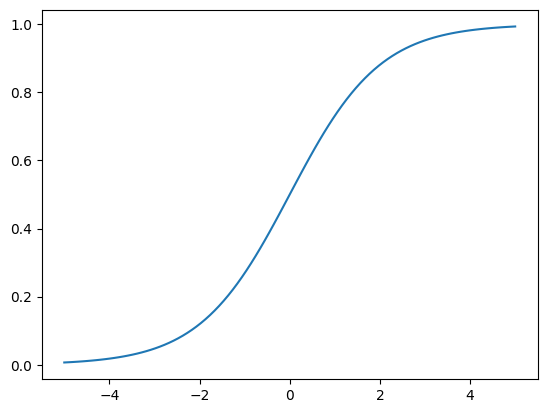

In [ ]:
z = np.linspace(-5, 5, 100)
p = sigmoid(z)

plt.plot(z, p);

In [ ]:
customers['churned'].mean()

np.float64(0.391)

In [ ]:
X = customers.drop(columns="churned")     # all 5 features
y = customers["churned"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("train:", X_train.shape, " test:", X_test.shape)

train: (800, 5)  test: (200, 5)


In [ ]:
X1 = X_train[['support_calls']]

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X1 , y_train)

LogisticRegression()

In [ ]:
print("coef:     ", model.coef_[0][0].round(3))
print("intercept:", model.intercept_[0].round(3))

coef:      0.978
intercept: -3.03


In [ ]:
# 1. z = 0.978*support_calls -3.03
# 2. p = sigmoid(z)

In [ ]:
# customer 1 : 5 calls
z = 0.978*5 -3.03
p = sigmoid(z)
p

np.float64(0.8652969480479719)

In [ ]:
# customer 2 : 1 call
z = 0.978*1 -3.03
p = sigmoid(z)
p

np.float64(0.11385044834696259)

In [ ]:
new_customers = np.array([[5], [1]])
new_customers

array([[5],
       [1]])

In [ ]:
model.predict(new_customers)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([1, 0])

In [ ]:
model.predict_proba(new_customers)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([[0.1346487 , 0.8653513 ],
       [0.88614201, 0.11385799]])

In [ ]:
y_pred = model.predict(X_test[['support_calls']])

In [ ]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.795

In [ ]:
sigmoid(-1)

np.float64(0.2689414213699951)

In [ ]:
p3 = sigmoid(0.978*3 -3.03)
odds3 = p3/(1-p3)
odds3

np.float64(0.9084640160687064)

In [ ]:
p4 = sigmoid(0.978*4 -3.03)
odds4 = p4/(1-p4)
odds4

np.float64(2.4157263308455987)

In [ ]:
odds4/odds3

np.float64(2.6591326548072094)

In [ ]:
model.coef_

array([[0.97809792]])

In [ ]:
np.exp(model.coef_)

array([[2.65939305]])

In [ ]:
# 2 extra calls?

In [ ]:
# 3 support vs 5 supports

p5 = sigmoid(0.978*5 -3.03)
odds5 = p5/(1-p5)
odds5

np.float64(6.423736771429132)

In [ ]:
odds5/odds3

np.float64(7.070986475862034)

In [ ]:
model_final = LogisticRegression()
model_final.fit(X_train, y_train)

LogisticRegression()

In [ ]:
coefs = pd.Series(model_final.coef_[0], index=X.columns)
print(coefs.round(3))
print("intercept:", model_final.intercept_[0].round(3))

support_calls     1.278
tenure_years     -0.324
monthly_bill_k    0.904
has_contract     -1.427
late_payments     0.513
dtype: float64
intercept: -2.999


In [ ]:
np.exp(coefs)

,0
support_calls,3.590218
tenure_years,0.723298
monthly_bill_k,2.468869
has_contract,0.239927
late_payments,1.669990


In [ ]:
y_pred = model_final.predict(X_test)
y_pred

array([0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0,
       0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0,
       1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1,
       0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1,
       1, 0])

In [ ]:
accuracy_score(y_test, y_pred)

0.845

In [ ]:
new_customer  = [[4, 2, 1.5, 1, 1]]

In [ ]:
model_final.predict(new_customer)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([1])

In [ ]:
model_final.predict_proba(new_customer)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([[0.12934922, 0.87065078]])